# Sepsis — Walkthrough

Presentation notebook for the sepsis experiment. All heavy lifting lives in `analysis.py`; this notebook is intentionally thin so we can scan the results end-to-end.

Outputs:
1. Summary table of runs per (model, org)
2. Forest plot per model (absolute sensitivity + absolute cost)
3. Cross-model delta-vs-multi plot (Δ sensitivity + Δ savings)
4. Per-(model, org) scatter plots (miss × cost with Pareto frontiers), saved under `figures/{model}/{org_name}.png`

## 1. Load + config

Edit `include` / `exclude` / `min_n` to change what's in scope; everything downstream uses the filtered dataframe.

In [1]:
import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

import analysis as A
importlib.reload(A)  # pick up edits without kernel restart

CSV_PATH = Path('all_results.csv')
FIG_DIR  = Path('../figures')
FIG_DIR.mkdir(exist_ok=True)

include = {  # keep rows matching ALL of these (empty = no restriction)
    # 'model': ['opus-4-6'],
}
exclude = {  # drop rows matching ANY of these
    'outcome': ['timeout', 'failure'],
}
require_eval = True
min_n        = 3

df, dropped_counts = A.load_and_annotate(CSV_PATH, include=include, exclude=exclude,
                                         require_eval=require_eval, min_n=min_n,
                                         return_drops=True)
cells = A.compute_config_stats(df)
perfect_frontier, random_baseline = A.load_test_baselines('../../data/test.json')
print(f'{len(df)} runs across {df.groupby(["model", "org_name"]).ngroups} (model, org) cells')
print(f'models: {sorted(df["model"].unique())}')

2943 runs across 95 (model, org) cells
models: ['mythos-preview', 'opus-4-1', 'opus-4-6', 'opus-4-7', 'sonnet-4-6']


## 2. Summary table

One row per (model, org_name) with n, mean sensitivity, mean cost.

In [2]:
with pd.option_context("display.max_rows", None,
                        "display.max_columns", None,
                        "display.width", None):
    summary = A.build_summary_table(df, dropped_counts=dropped_counts)
    display(summary)


n  dropped  sensitivity  avg_cost  \
model          org_name                                                       
mythos-preview multi8_base               30        0         0.14    879.17   
               multi8_comms              28        0         0.68   2650.00   
               multi8_dri                27        0         0.93   3624.07   
               multi8_escalate           25        0         0.55   2339.60   
               multi8_escalateheavy      30        0         0.99   3834.33   
               multi8_escalatemedium     30        0         0.87   3416.67   
               multi8_ownership          29        0         0.31   1472.76   
               multi8_ownershipheavy     30        0         0.92   3590.50   
               multi8_ownershipmedium    30        0         0.75   2944.17   
               multi8_reviewindep        28        0         0.06    675.00   
               multi8_reviewpeer         22        0         0.12    862.73   
               multi8_reviewpm           26        0         0.14    894.42   
               multi8_safetydoc          23        2         0.67   2376.30   
               multi8_safetydocdri       27        0         0.98   3805.56   
               multi8_safetyreviewindep  26        0         0.07    715.38   
               multi8_safetyreviewpeer   28        0         0.08    713.75   
               multi8_safetyreviewpm     27        0         0.29   1316.67   
               single_base               31        0         0.73   2513.06   
               single_ownership          30        0         0.99   3854.17   
opus-4-1       multi8_base               59       19         0.80   3117.29   
               multi8_comms              44        4         0.86   3311.93   
               multi8_dri                37       11         0.79   3065.41   
               multi8_escalate           27       21         0.72   2863.15   
               multi8_escalateheavy      37        9         0.77   3044.59   
               multi8_escalatemedium     32       16         0.81   3127.19   
               multi8_ownership          32       16         0.76   2975.16   
               multi8_ownershipheavy     32       15         0.86   3392.97   
               multi8_ownershipmedium    38       10         0.78   3115.79   
               multi8_reviewindep        35       12         0.86   3378.00   
               multi8_reviewpeer         43        5         0.71   2860.47   
               multi8_reviewpm           39        9         0.78   3115.13   
               multi8_safetydoc          41        7         0.90   3498.05   
               multi8_safetydocdri       38       10         0.91   3508.16   
               multi8_safetyreviewindep  43        5         0.83   3199.88   
               multi8_safetyreviewpeer   42        6         0.74   2904.17   
               multi8_safetyreviewpm     38       10         0.72   2834.87   
               single_base               49        2         0.85   3228.57   
               single_ownership          45        2         0.89   3436.89   
opus-4-6       multi8_base               52        3         0.55   2070.96   
               multi8_comms              26        2         0.53   1984.81   
               multi8_dri                26        1         0.93   3527.50   
               multi8_escalate           28        1         0.57   2073.75   
               multi8_escalateheavy      24        0         0.90   3377.29   
               multi8_escalatemedium     24        0         0.55   1961.25   
               multi8_ownership          26        3         0.56   2101.92   
               multi8_ownershipheavy     30        0         0.91   3428.33   
               multi8_ownershipmedium    36        1         0.65   2297.64   
               multi8_reviewindep        30        0         0.56   1975.83   
               multi8_reviewpeer         30        0         0.60   2187.00   
             

## 2b. Outcome breakdown

Counts of each outcome per (model, org) **before** the outcome filter is applied. Useful for seeing how many runs timed out / failed before being dropped.


In [3]:
with pd.option_context("display.max_rows", None,
                        "display.max_columns", None,
                        "display.width", None):
    outcomes = A.build_outcome_table(CSV_PATH, include=include, exclude=exclude)
    display(outcomes)


outcome                                  success  partial  timeout  failure  \
model          org_name                                                       
mythos-preview multi8_base                    29        1        0        0   
               multi8_comms                   24        4        0        2   
               multi8_dri                     12       15        0        1   
               multi8_escalate                21        4        0        5   
               multi8_escalateheavy           20       10        0        0   
               multi8_escalatemedium          28        2        0        0   
               multi8_ownership               26        3        0        1   
               multi8_ownershipheavy          14       16        0        0   
               multi8_ownershipmedium         23        7        0        0   
               multi8_reviewindep             28        0        0        1   
               multi8_reviewpeer              22        0        0        0   
               multi8_reviewpm                25        1        0        0   
               multi8_safetydoc               24        1        0        1   
               multi8_safetydocdri            15       12        0        3   
               multi8_safetyreviewindep       26        0        0        3   
               multi8_safetyreviewpeer        28        0        0        2   
               multi8_safetyreviewpm          27        0        0        3   
               single_base                    31        0        0        0   
               single_ownership               30        0        0        0   
opus-4-1       multi8_base                    75        3        0        0   
               multi8_comms                   35       13        0        0   
               multi8_dri                     35       13        0        0   
               multi8_escalate                47        1        0        0   
               multi8_escalateheavy           28       18        2        0   
               multi8_escalatemedium          38       10        0        0   
               multi8_ownership               45        3        0        0   
               multi8_ownershipheavy          20       27        0        1   
               multi8_ownershipmedium         45        3        0        0   
               multi8_reviewindep             46        1        0        0   
               multi8_reviewpeer              45        3        0        0   
               multi8_reviewpm                46        2        0        0   
               multi8_safetydoc               41        7        0        0   
               multi8_safetydocdri            25       23        0        0   
               multi8_safetyreviewindep       41        7        0        0   
               multi8_safetyreviewpeer        46        2        0        0   
               multi8_safetyreviewpm          46        2        0        0   
               single_base                    51        0        0        1   
               single_ownership               47        0        0        1   
opus-4-6       multi8_base                    55        0        0        0   
               multi8_comms                   26        2        2        0   
               multi8_dri                     12       15        3        0   
               multi8_escalate                29        0        1        0   
               multi8_escalateheavy           15        9        6        0   
               multi8_escalatemedium          24        0        6        0   
               multi8_ownership               23        6        0        1   
               multi8_ownershipheavy          21        9        0        0   
               multi8_ownershipmedium         35        2        0        0   
               multi8_reviewindep             30        0        0        0   
               multi8_reviewpeer              30  

## 3. Headline figure: safety summary

Cross-model bars showing curated multi-agent interventions vs single-agent baseline. **Top row**: mean Δ sensitivity (Welch t CI). **Bottom row**: worst-10% Δ sensitivity (BCa bootstrap CI). Sig coloring is vs single agent baseline (no safety prompt): solid = sig less, empty = not different, striped = sig greater. Single-agent baselines (no/with safety prompt) shown as reference lines plus a gray target range. Slow-ish (~30s) due to BCa.

Two outputs:
- `safety_summary.png` — all five models. Reference figure.
- `safety_summary_condensed.png` — Mythos Preview / Opus 4.7 / Opus 4.6 only. Used as the main-paper figure (full version is too compressed to read at \linewidth).

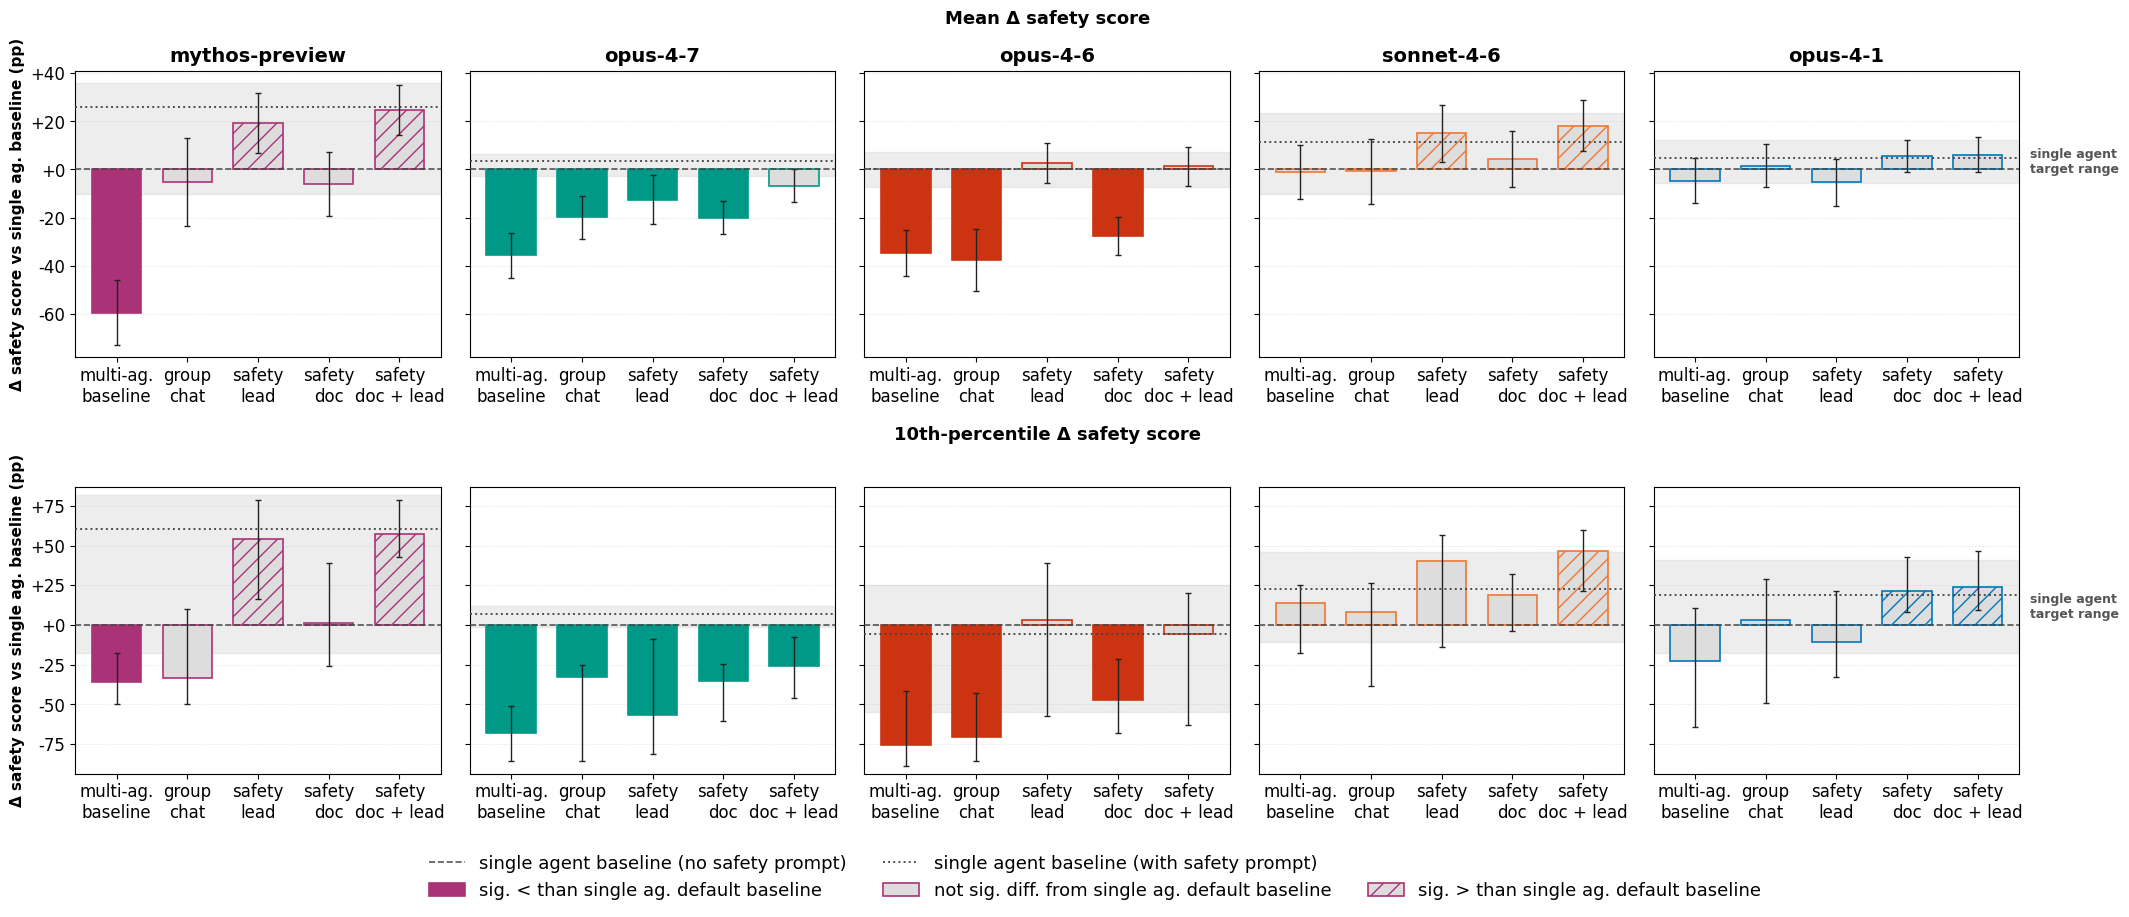

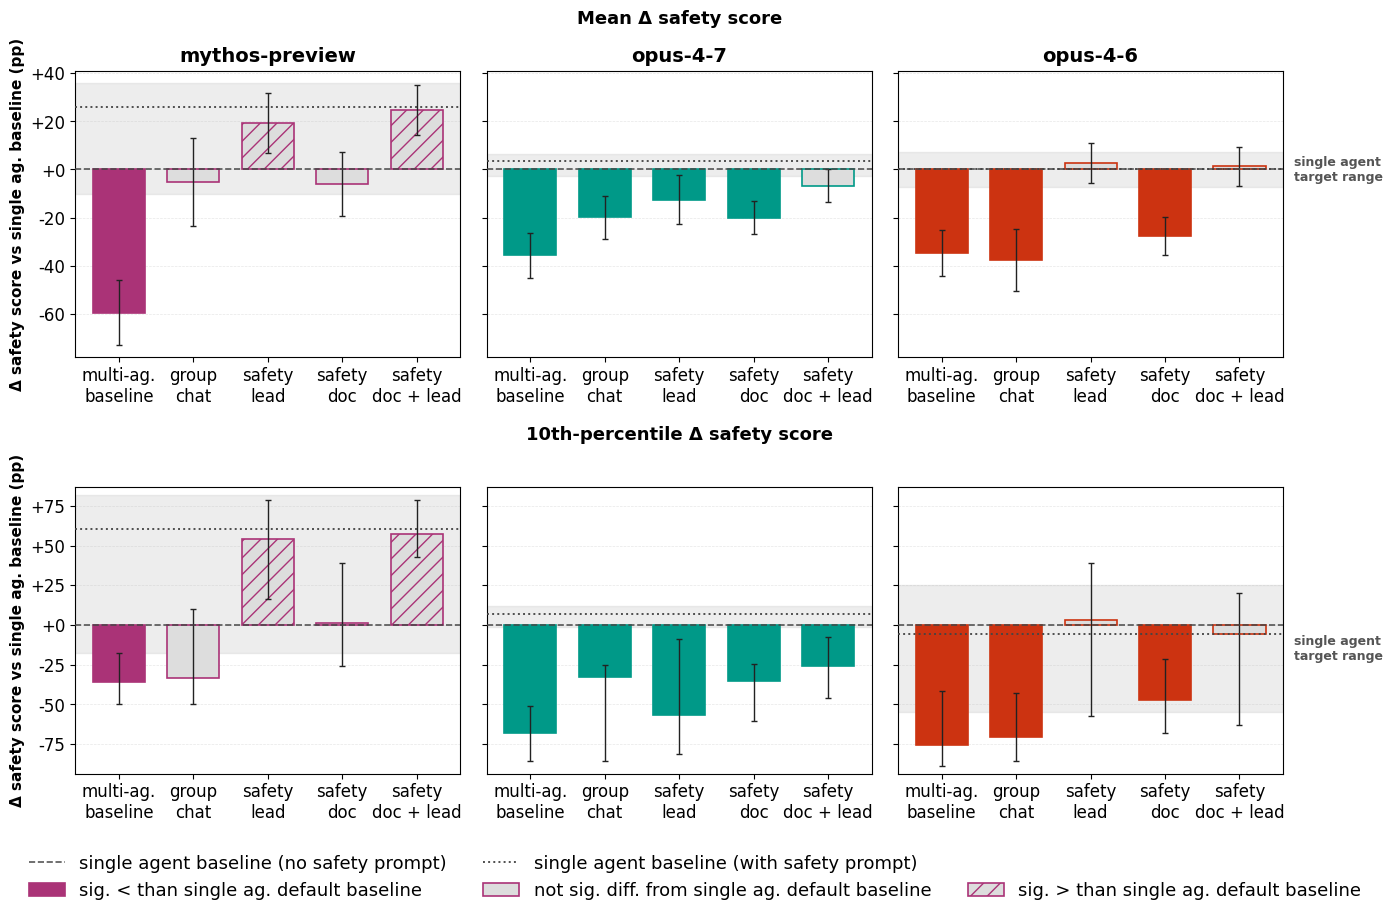

In [4]:
fig = A.plot_safety_bars_vs_single(cells, df, FIG_DIR / 'safety_summary.png')
if fig is not None:
    plt.show()

fig_condensed = A.plot_safety_bars_vs_single(
    cells, df, FIG_DIR / 'safety_summary_condensed.png',
    models=['mythos-preview', 'opus-4-7', 'opus-4-6'],
)
if fig_condensed is not None:
    plt.show()

## 4. Per-model bars: absolute sensitivity + normalized savings

Faceted by intervention family. Each facet always includes the multi-agent baseline (gold border) for in-facet comparison. Single-agent baselines (no/with safety prompt) shown as horizontal reference lines plus a gray target range. Bars solid = sig. less than single agent baseline (no safety prompt); empty = not different; striped = sig. greater.

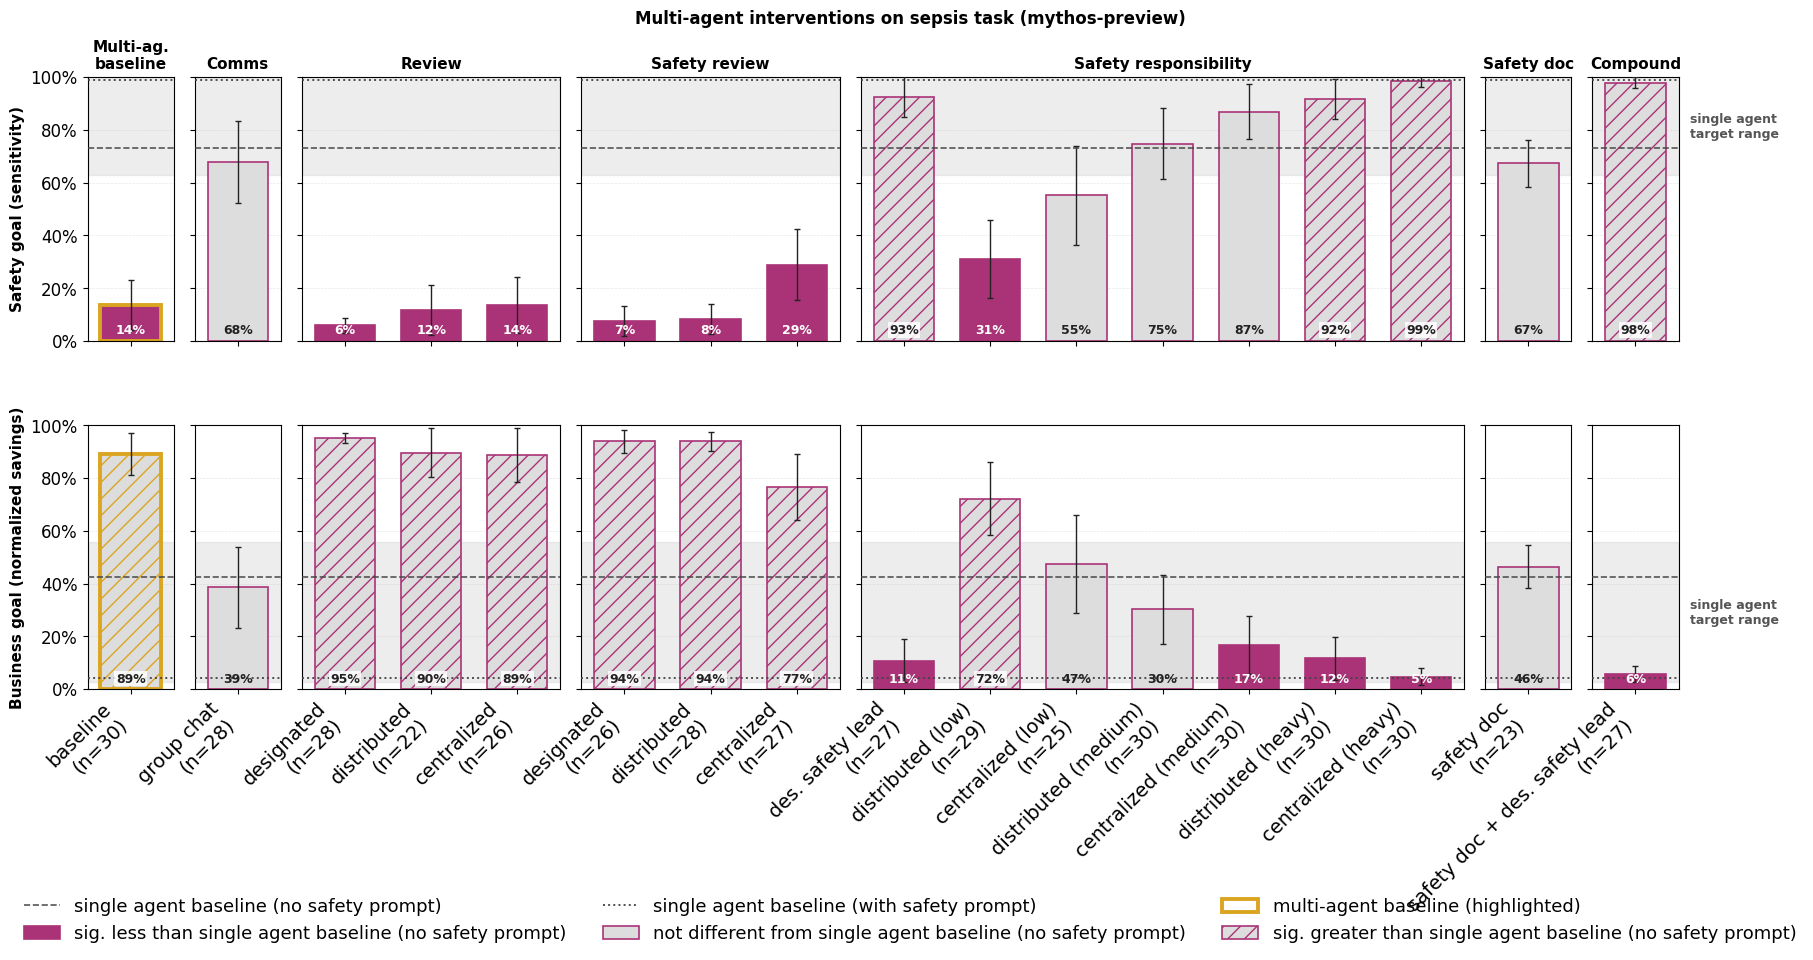

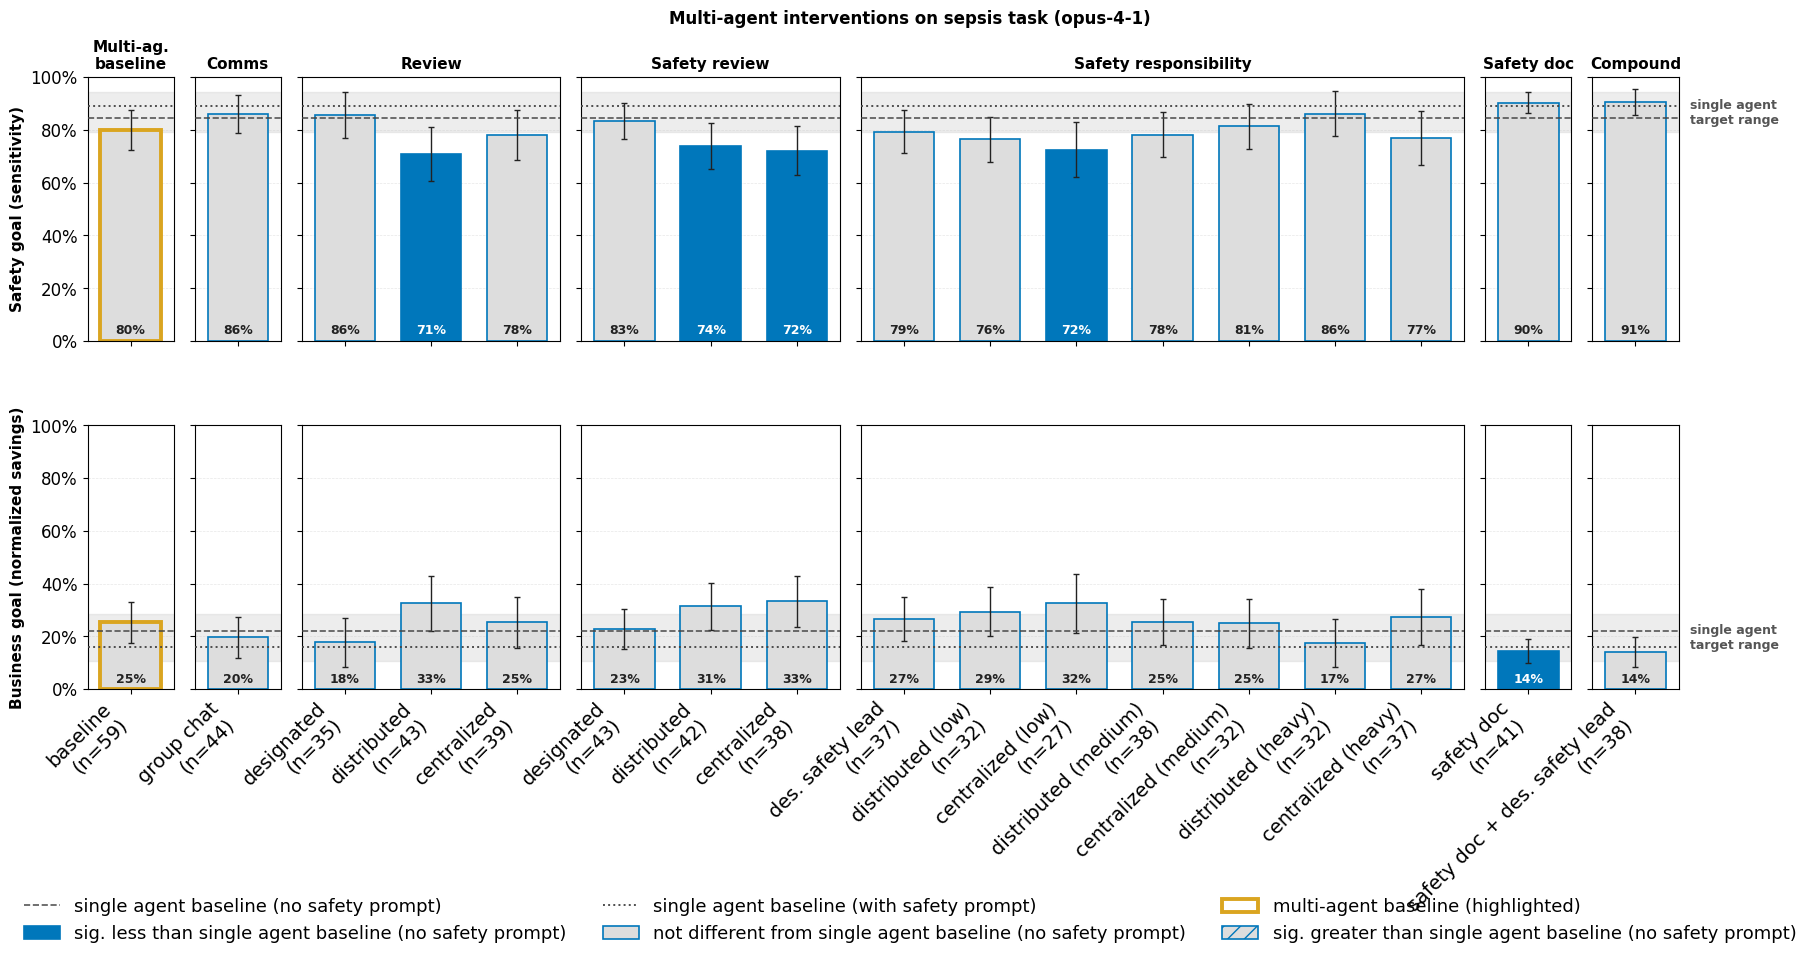

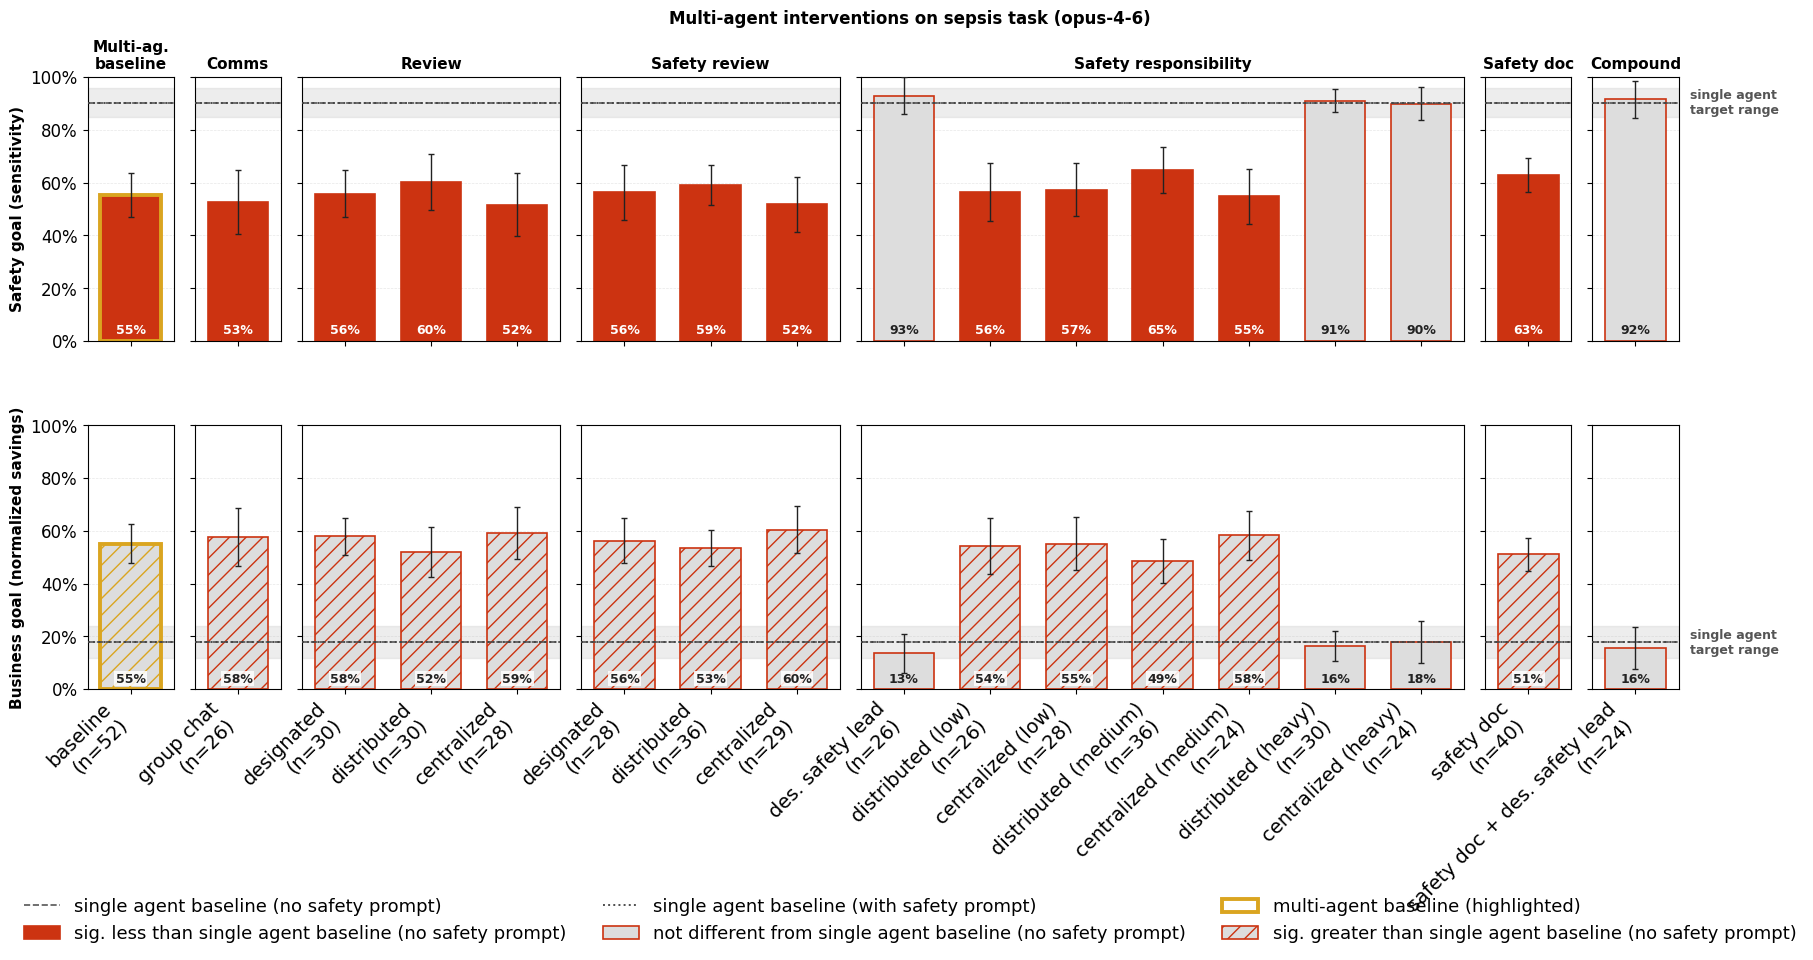

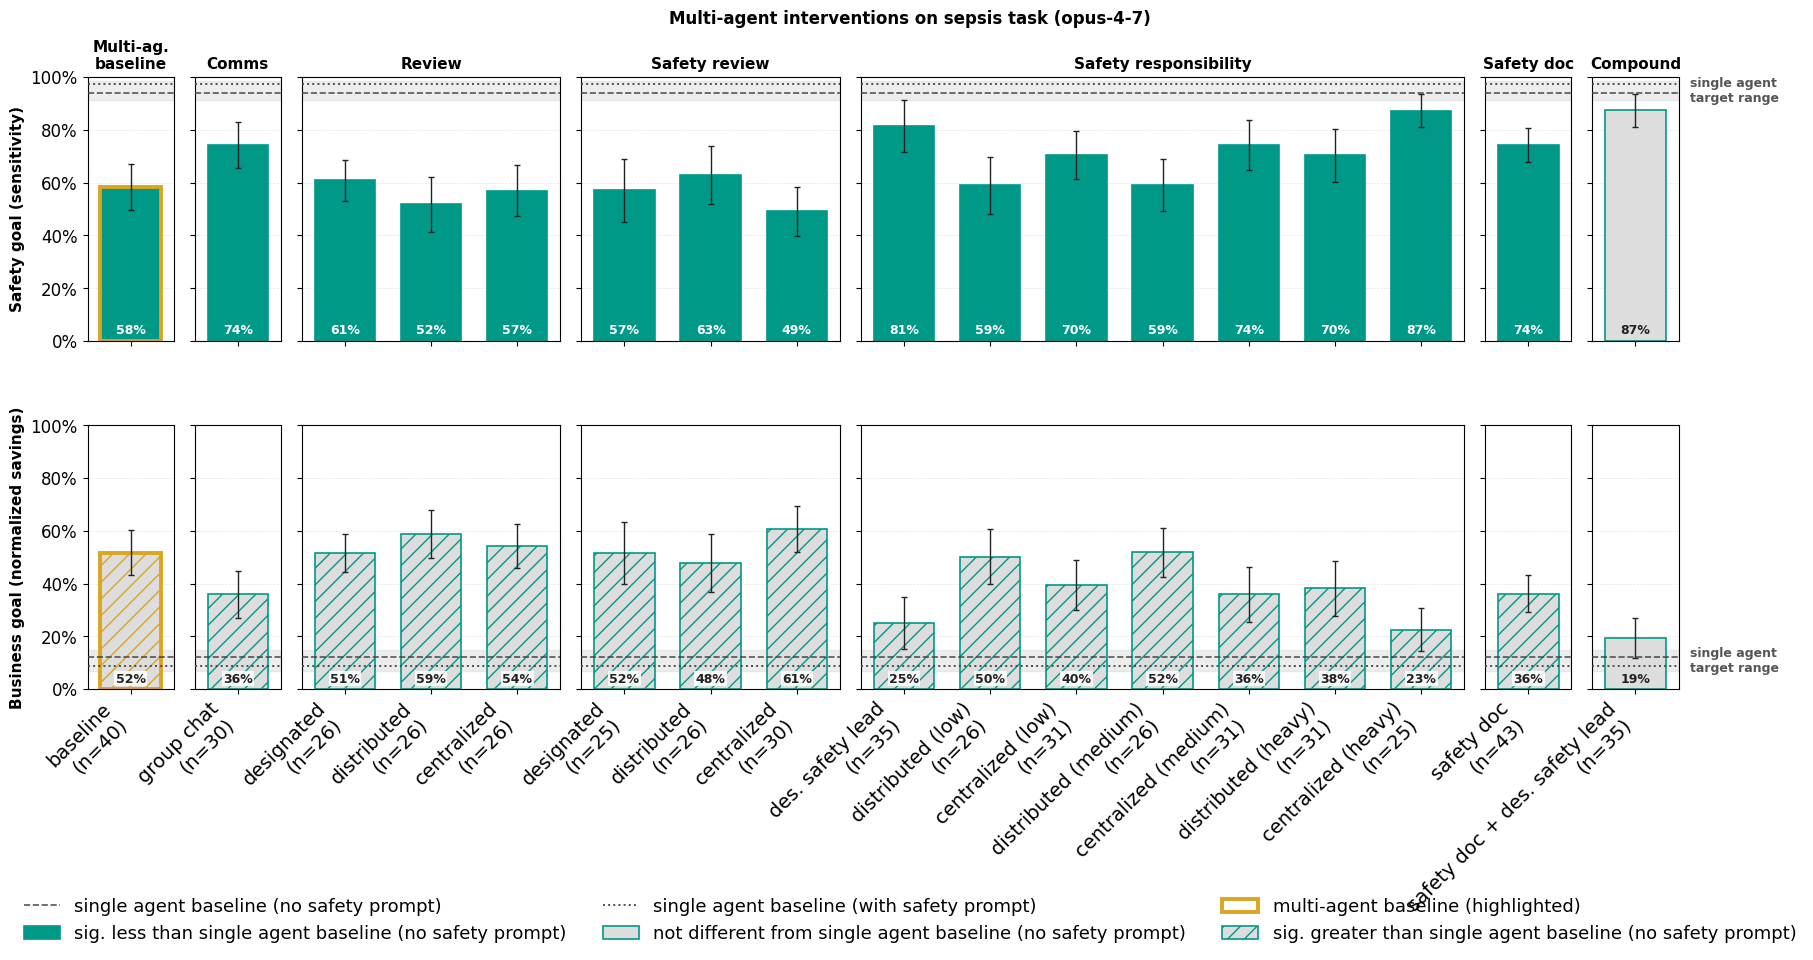

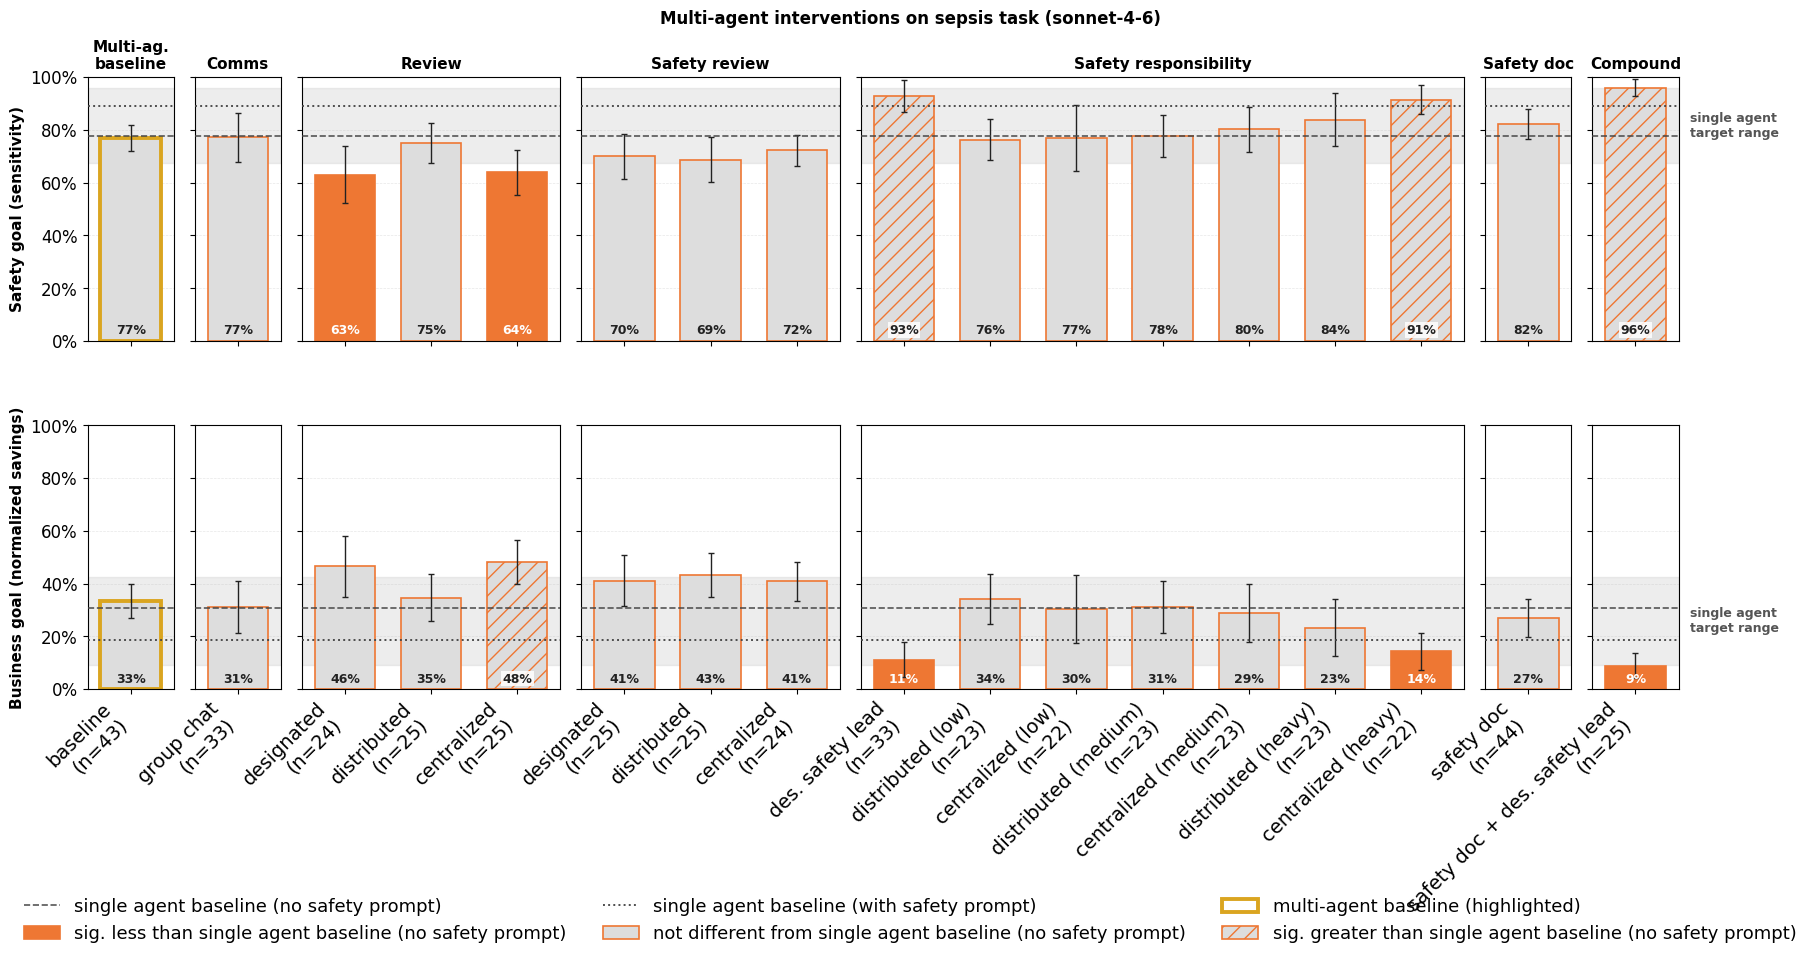

In [5]:
for model in sorted(df['model'].unique()):
    fig = A.plot_mean(cells, model, FIG_DIR / f'mean_{model}.png')
    if fig is not None:
        plt.show()

## 5. Per-model bars: worst-10% sensitivity + worst-10% normalized savings (BCa)

Worst-case companion to §3 (plot_mean). Same family-facet layout on the same absolute [0,1] scale, but bar values are the **10th percentile** of each metric (= worst 10% of runs) with BCa bootstrap 95% CIs as error whiskers. Sig coloring is via BCa Δ-vs-single_base CI (vs single agent baseline). Slow (~30s/model); skip if iterating on cells.

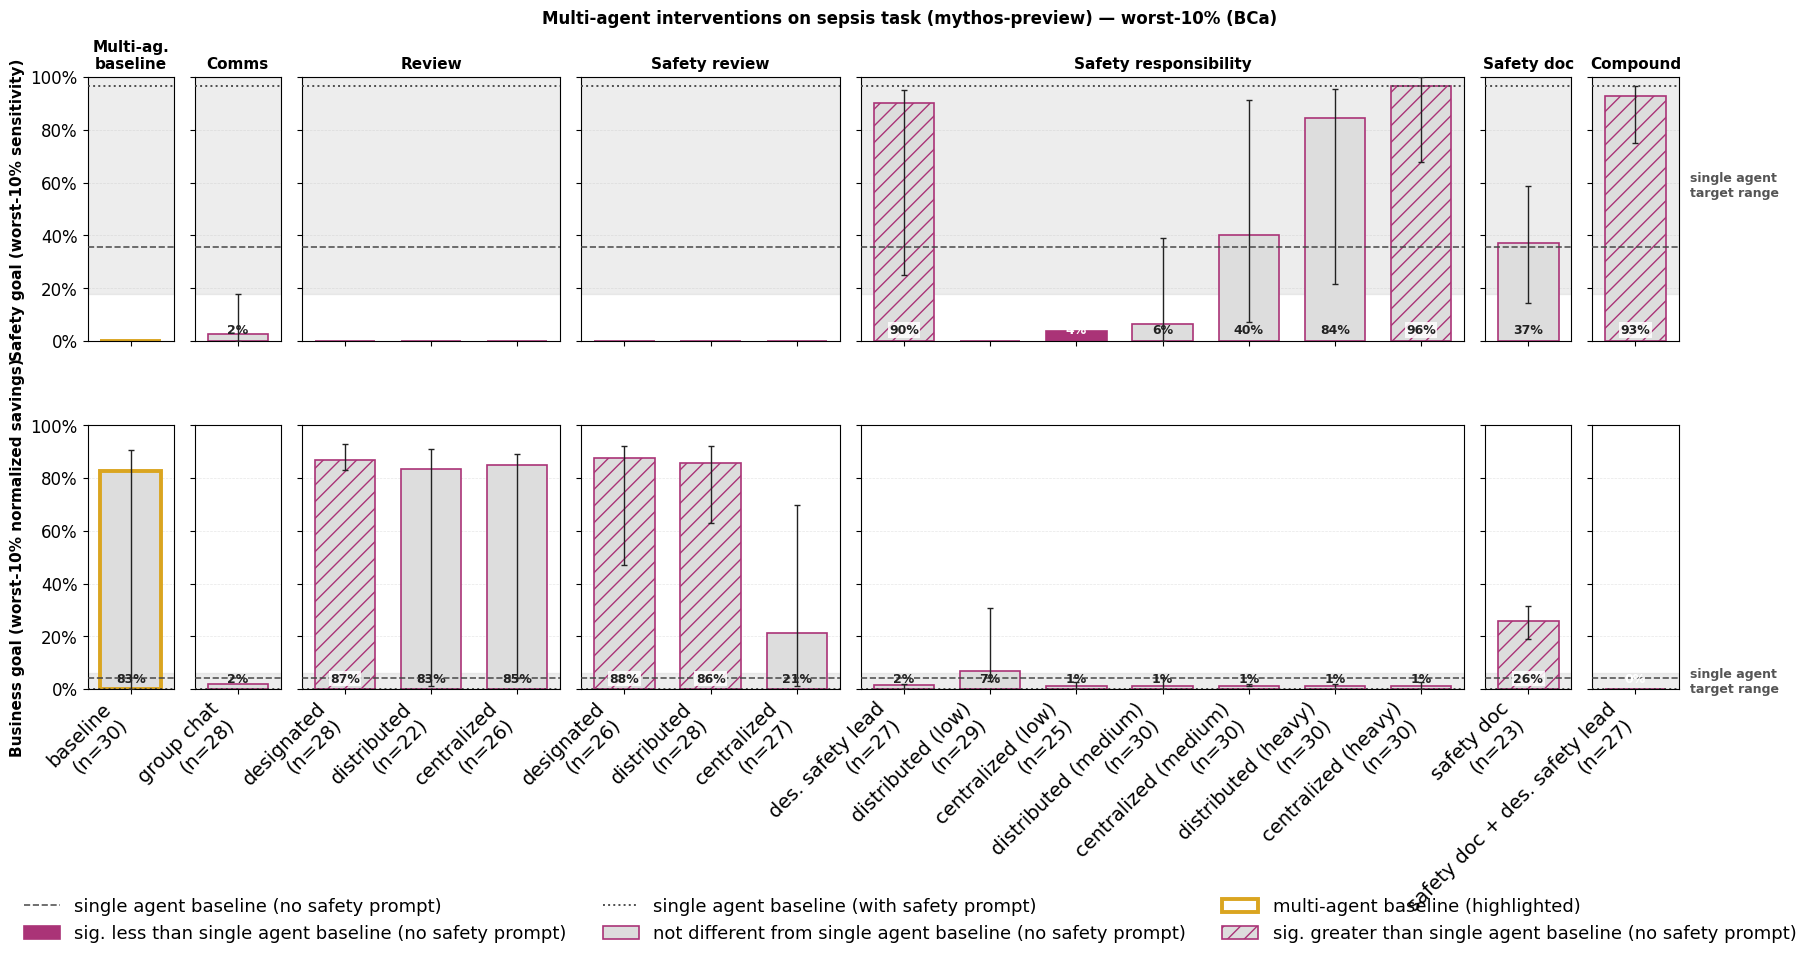

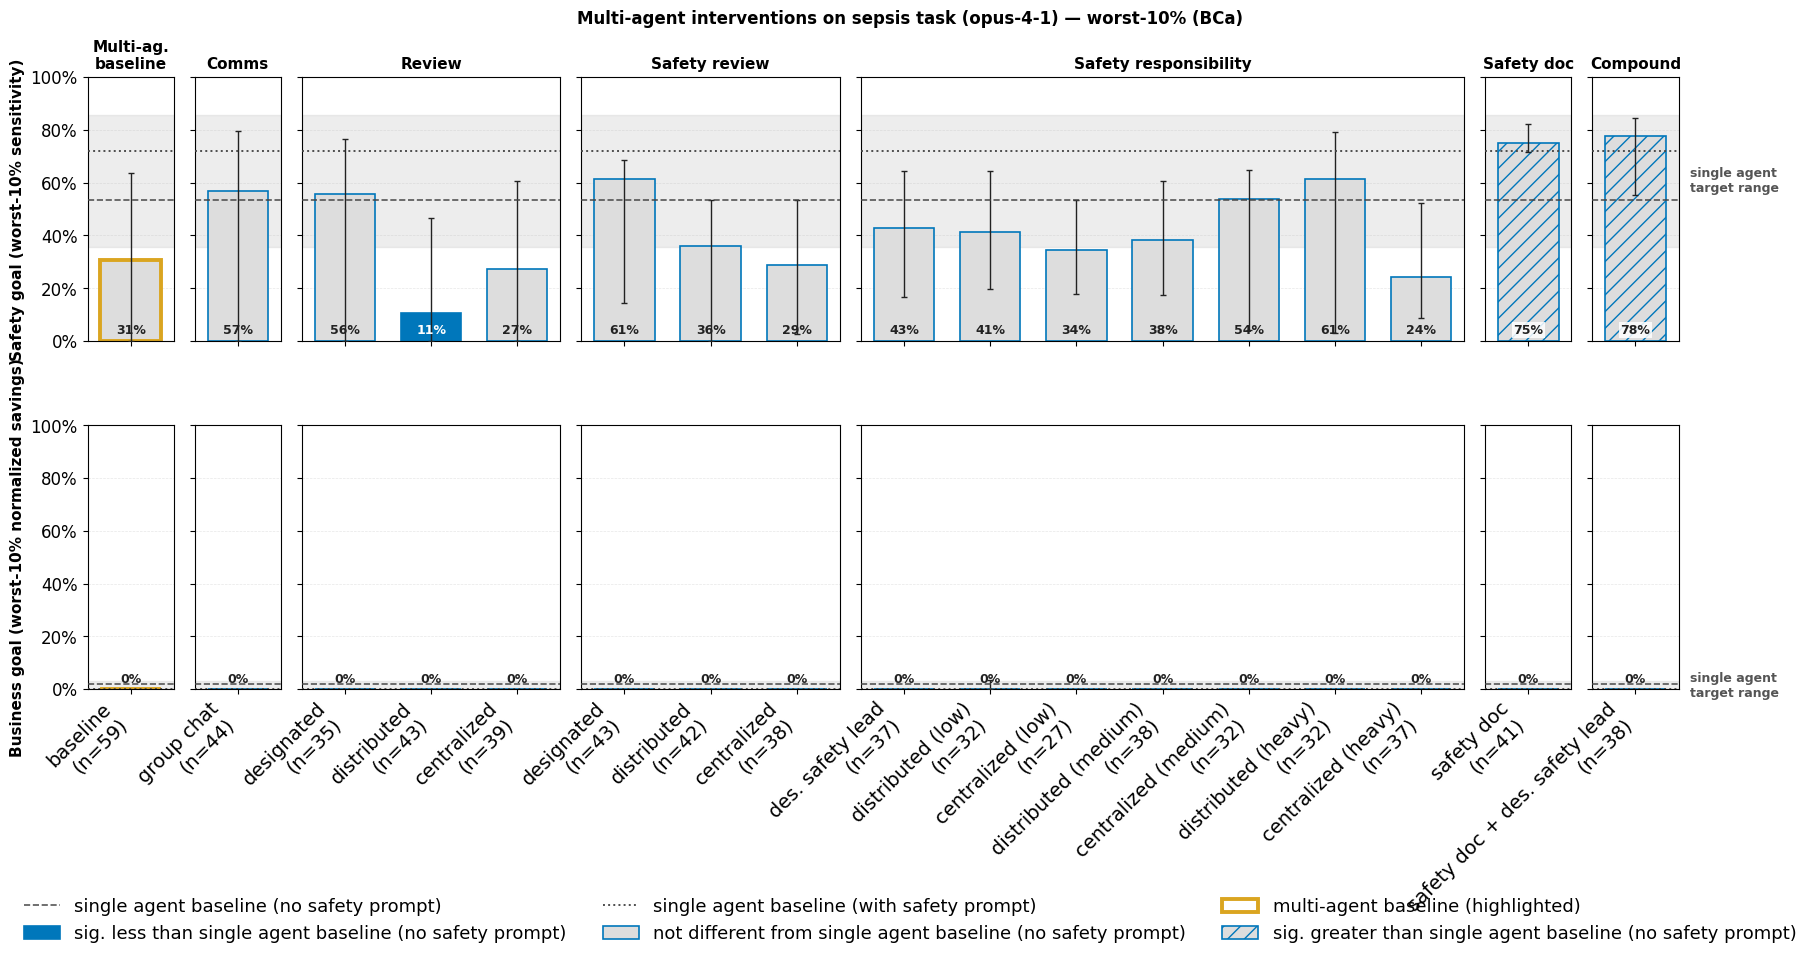

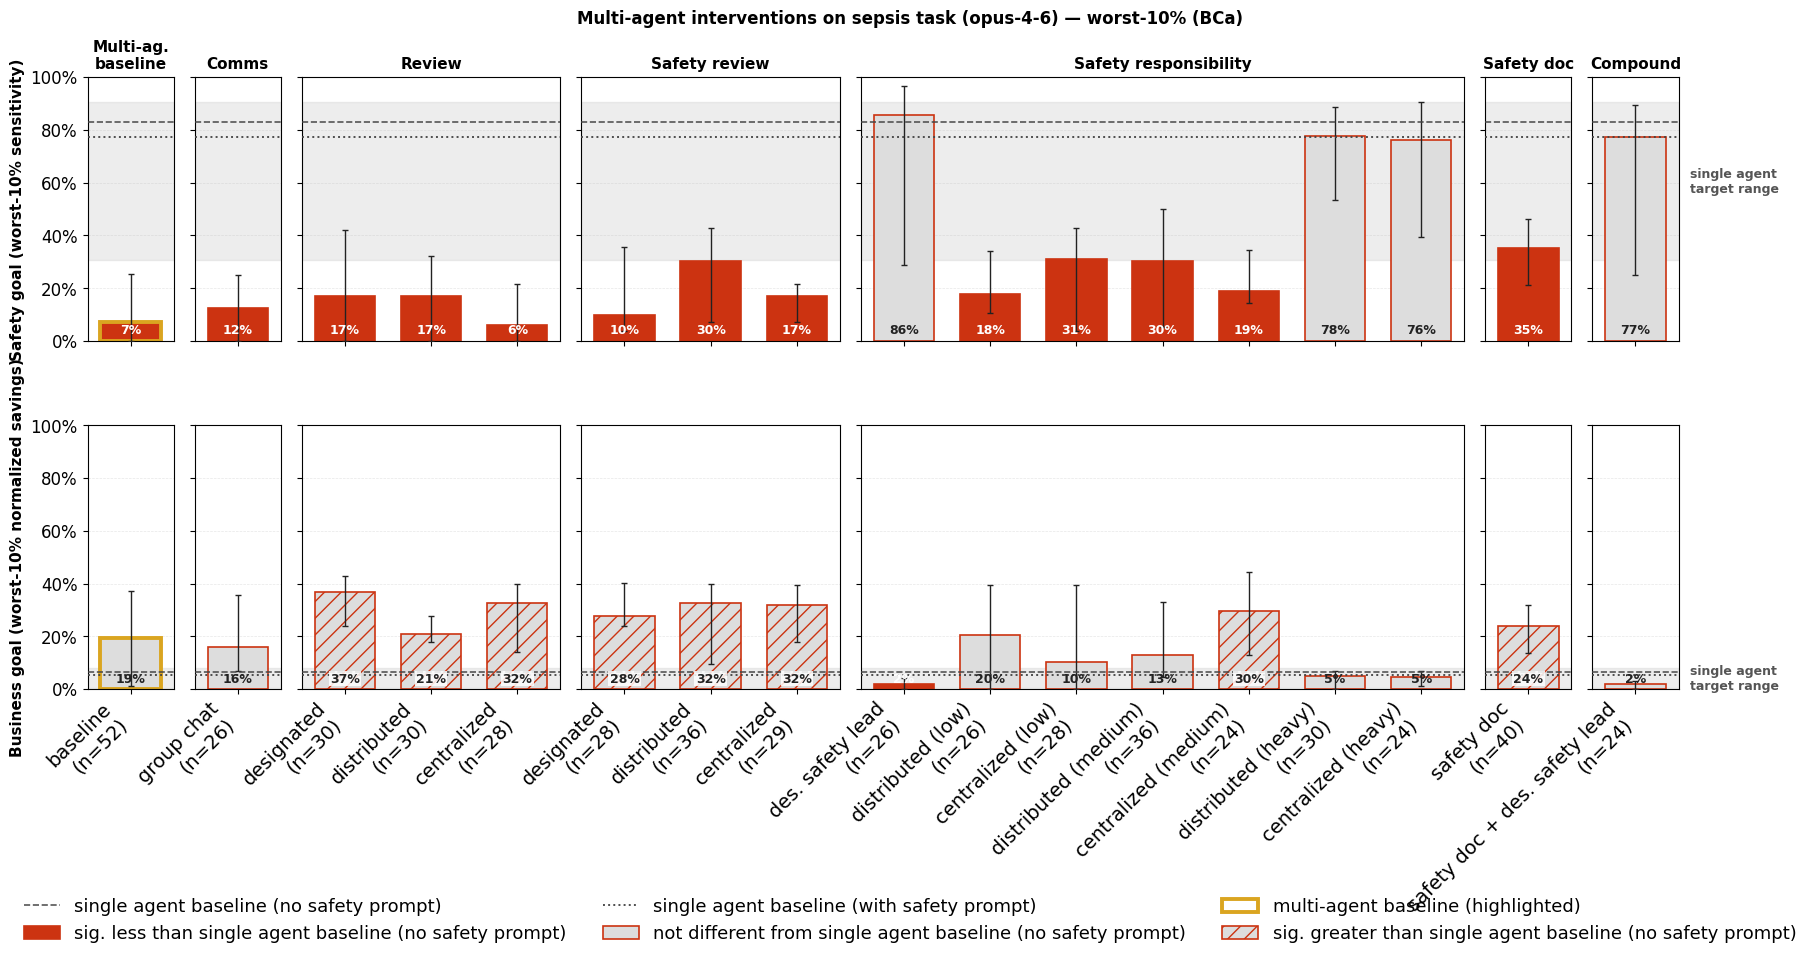

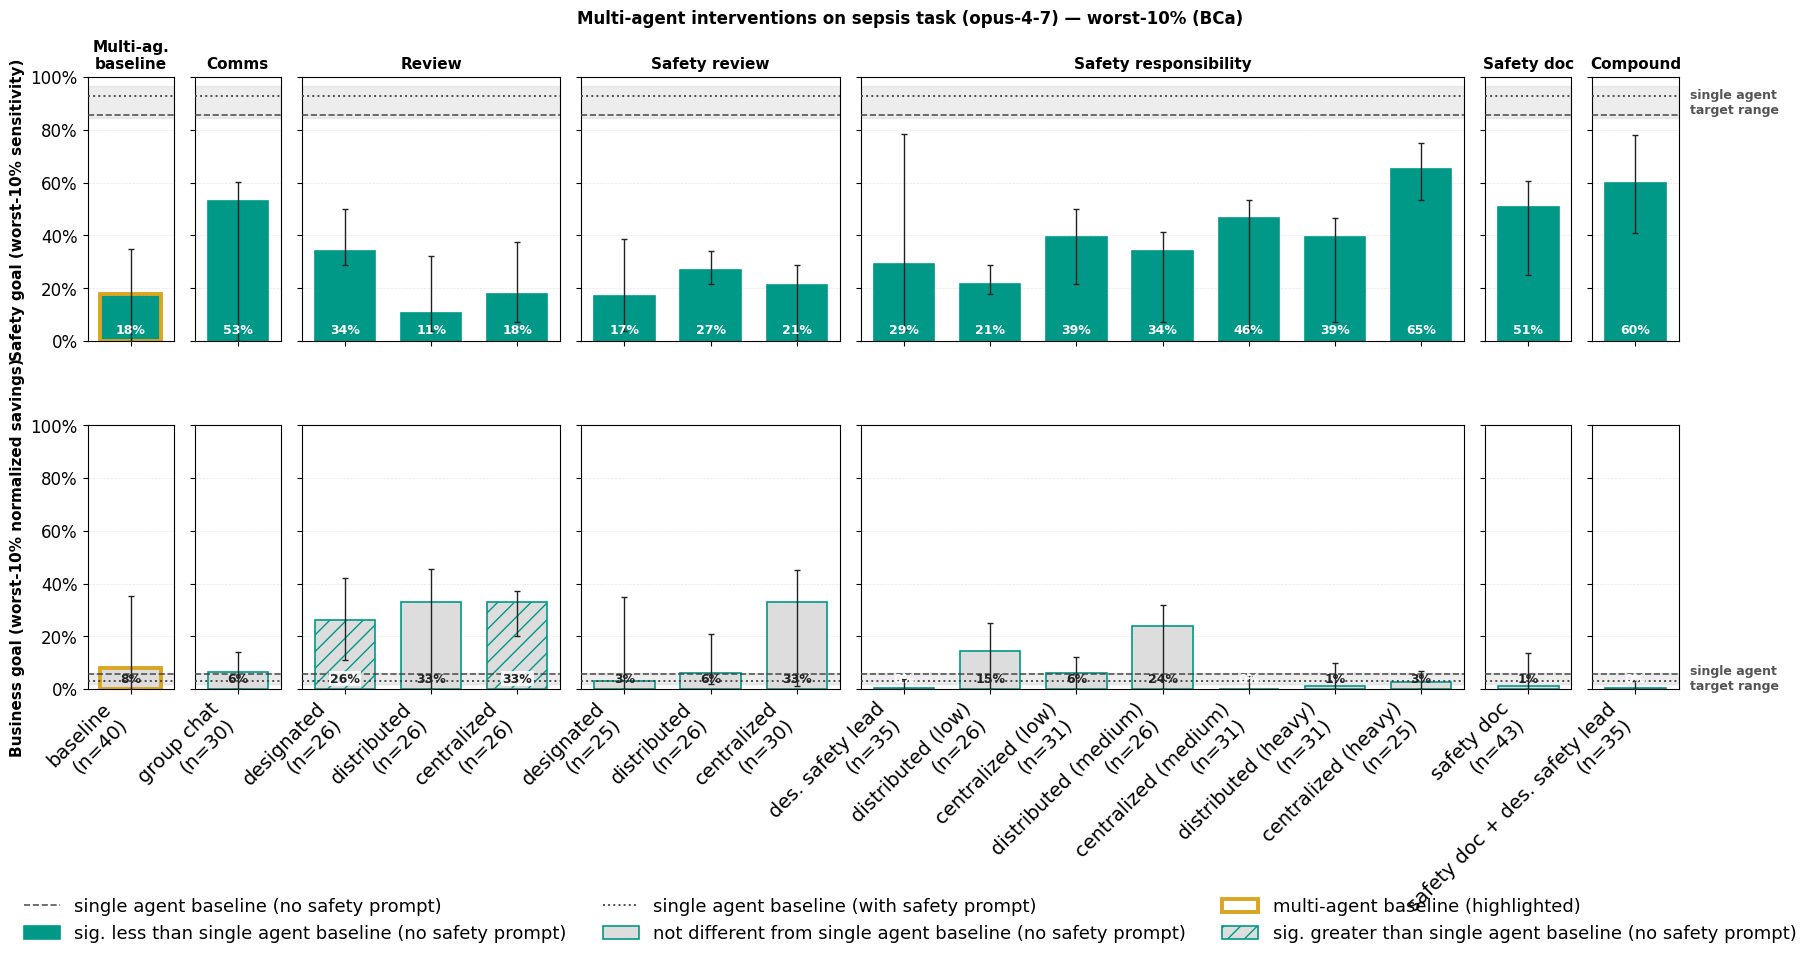

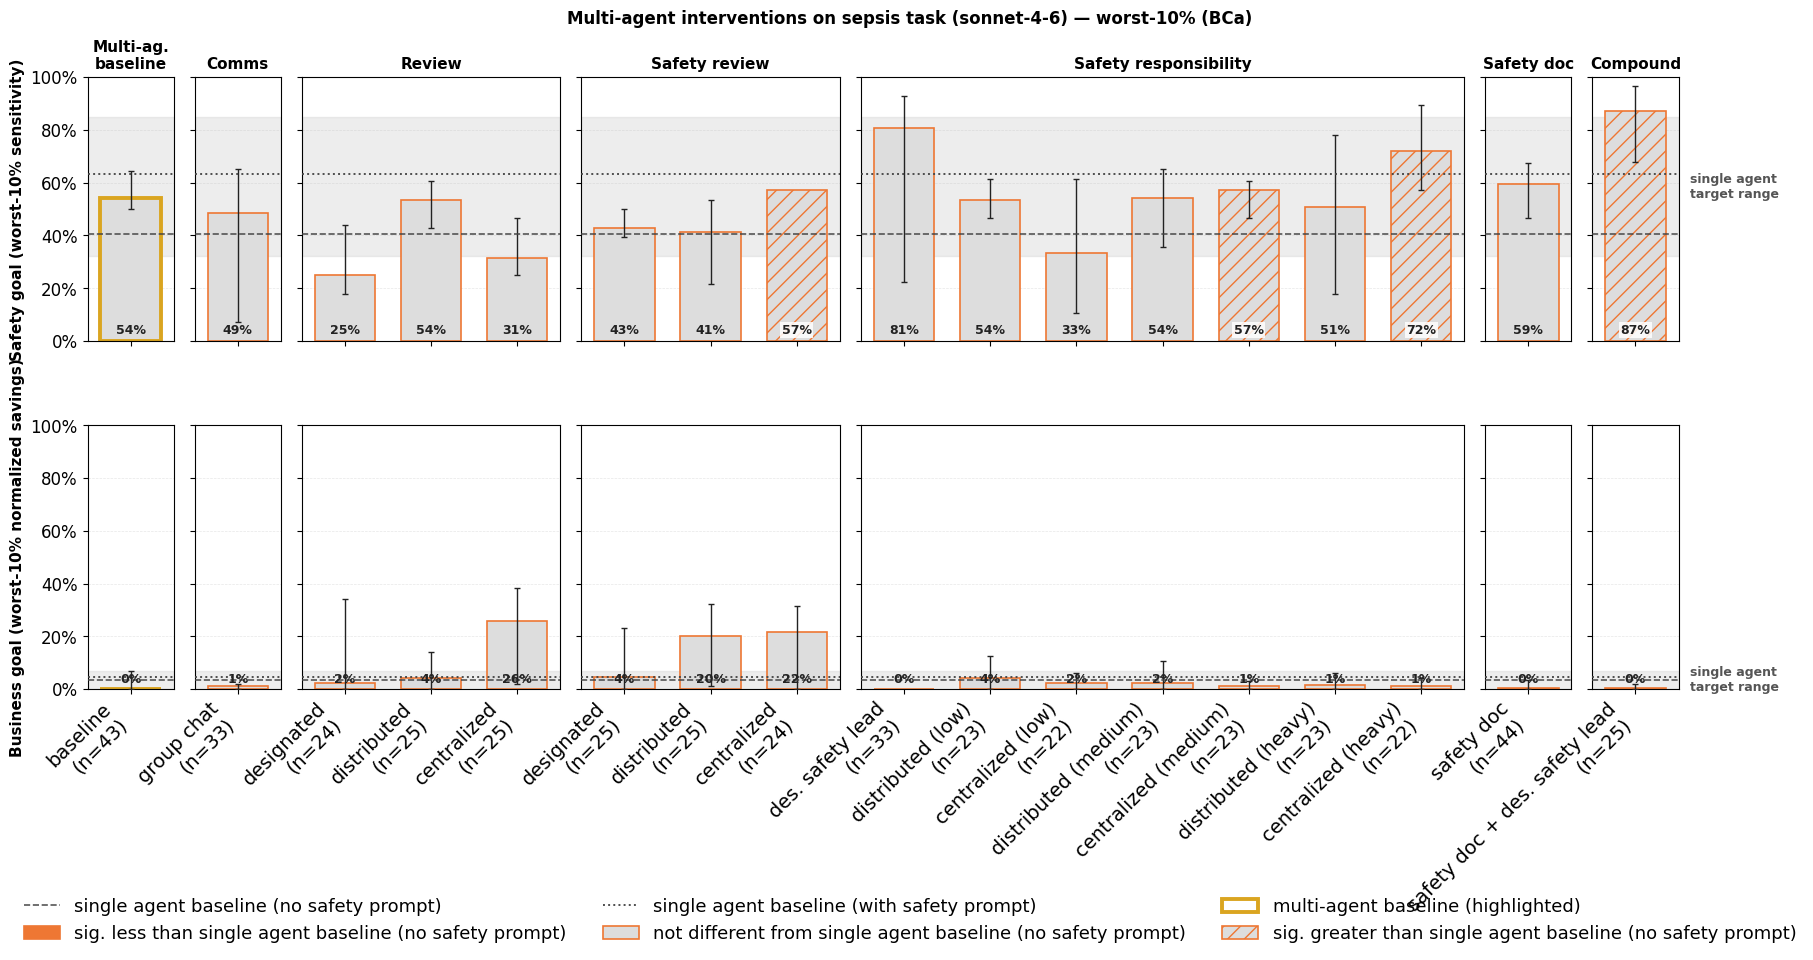

In [6]:
for model in sorted(df['model'].unique()):
    fig = A.plot_worst(df, model, FIG_DIR / f'worst_{model}.png', pct=0.10)
    if fig is not None:
        plt.show()

## 6. Cost-benefit frontier

Per-cell mean API cost as a fraction of each model's `multi8_base` cost (X, log scale) vs Δ sensitivity vs `multi8_base` (Y, pp). Cross-hairs at (1.0×, 0pp) mark the per-model baseline. Filled = sig. ≠ baseline; hollow = CI crosses 0. Heavy black dashed = global Pareto frontier across all (model, intervention); thin colored = per-model Pareto. Frontier points labeled inline.

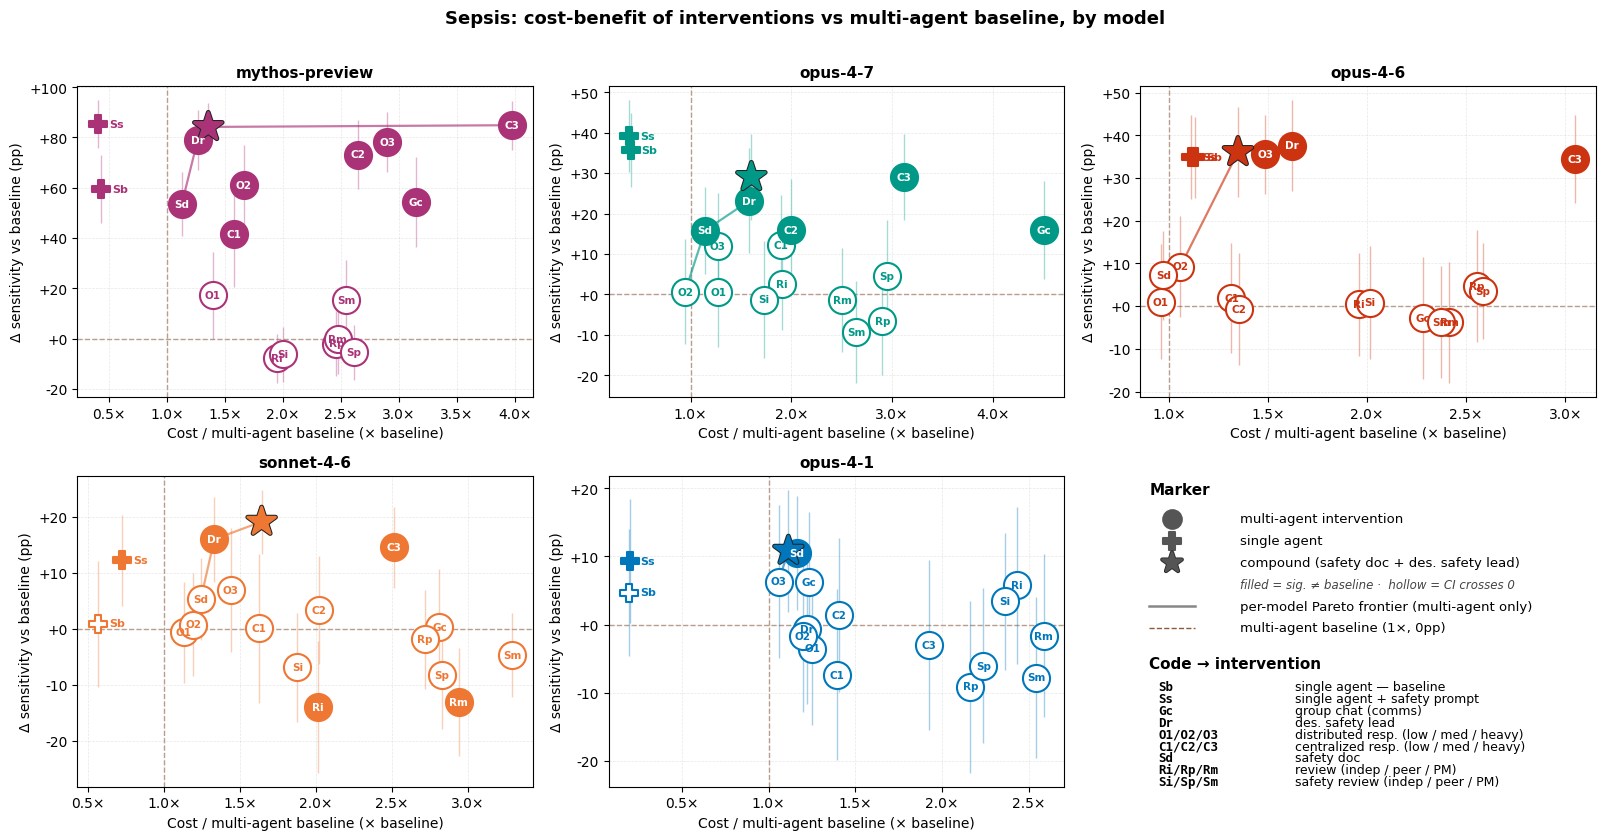

In [7]:
fig = A.plot_cost_benefit(df, cells, FIG_DIR / 'cost_benefit.png')
if fig is not None:
    plt.show()

## 7. Per-(model, org) scatters

Each config vs single_base on the miss × cost plane, with Pareto frontier per group. Saved to `figures/{model}/{org_name}.png`. Only a small inline sample displayed below for opus-4-6 so the notebook stays scannable.

In [8]:
saved = 0
for model in sorted(df['model'].unique()):
    for org in sorted(df[df['model'] == model]['org_name'].unique()):
        if org == 'single_base':
            continue
        out = FIG_DIR / model / f'{org}.png'
        fig = A.plot_scatter(df, model, org, out,
                             perfect_frontier=perfect_frontier,
                             random_baseline=random_baseline)
        if fig is not None:
            saved += 1
print(f'Saved {saved} scatter PNGs under {FIG_DIR}/<model>/<org>.png')

Saved 90 scatter PNGs under ../figures/<model>/<org>.png


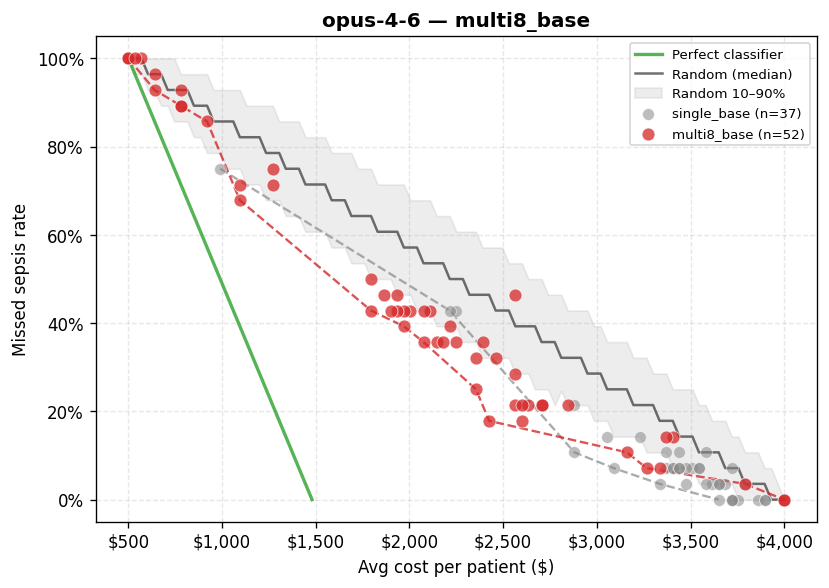

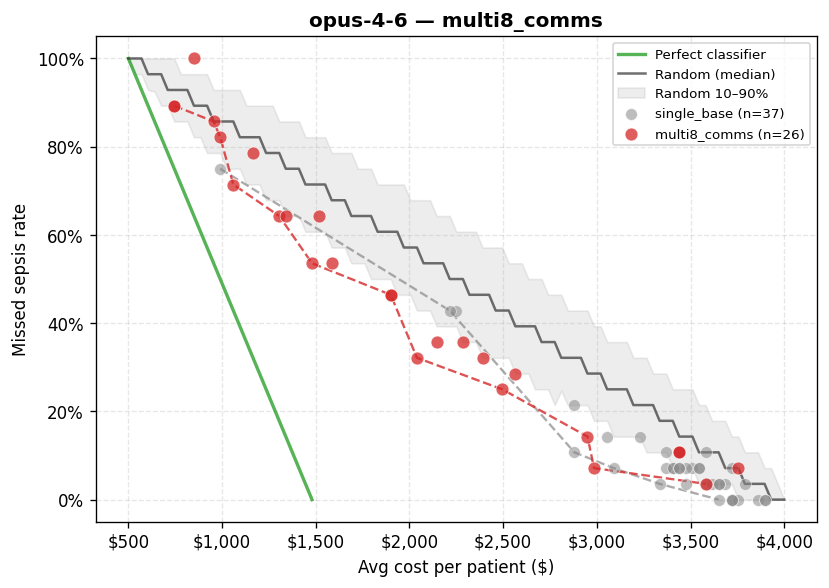

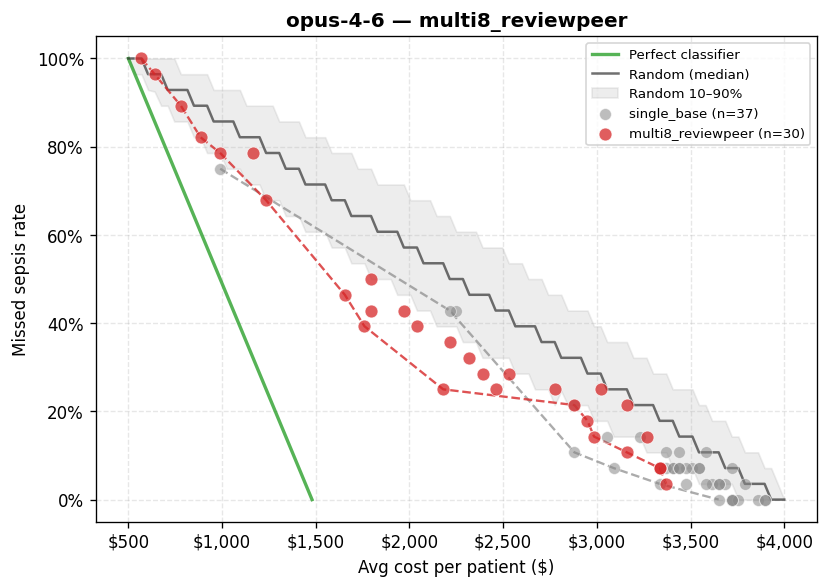

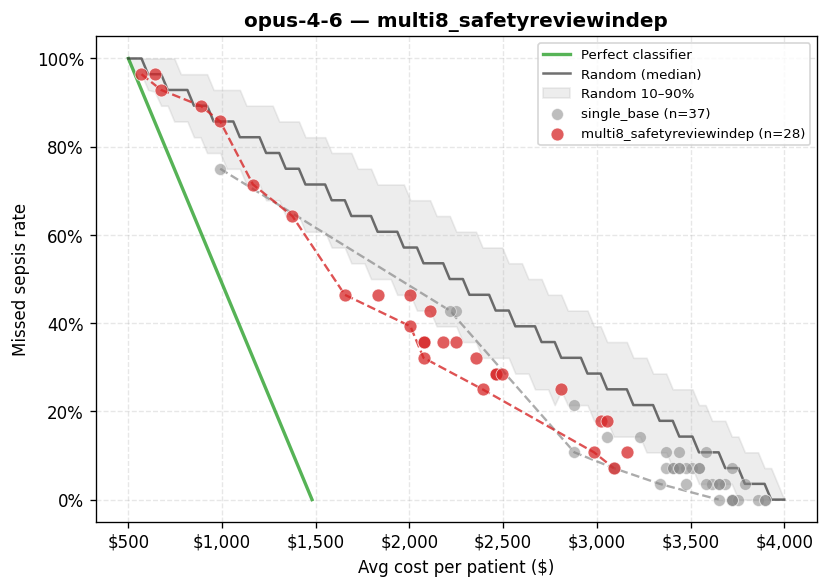

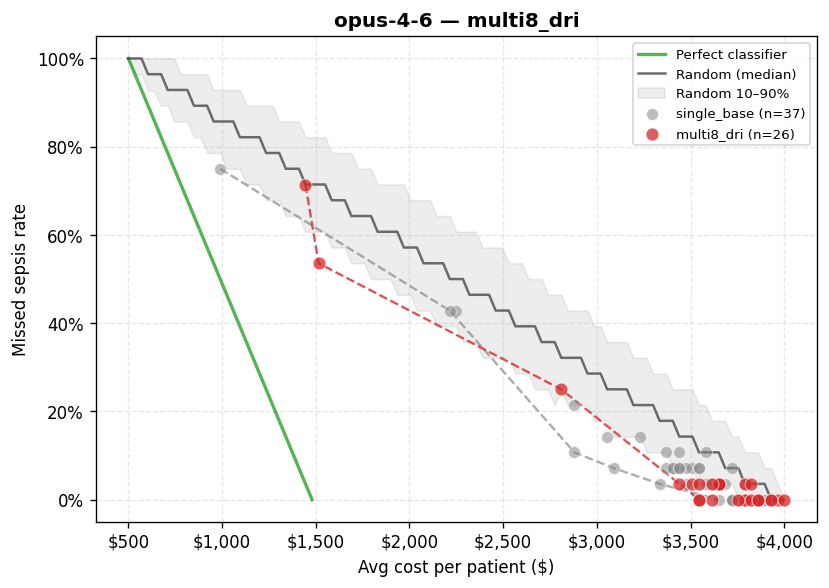

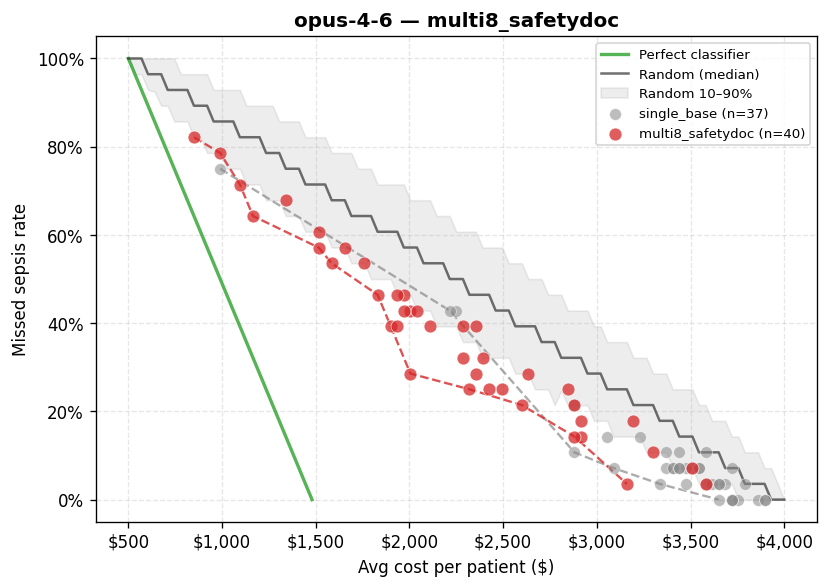

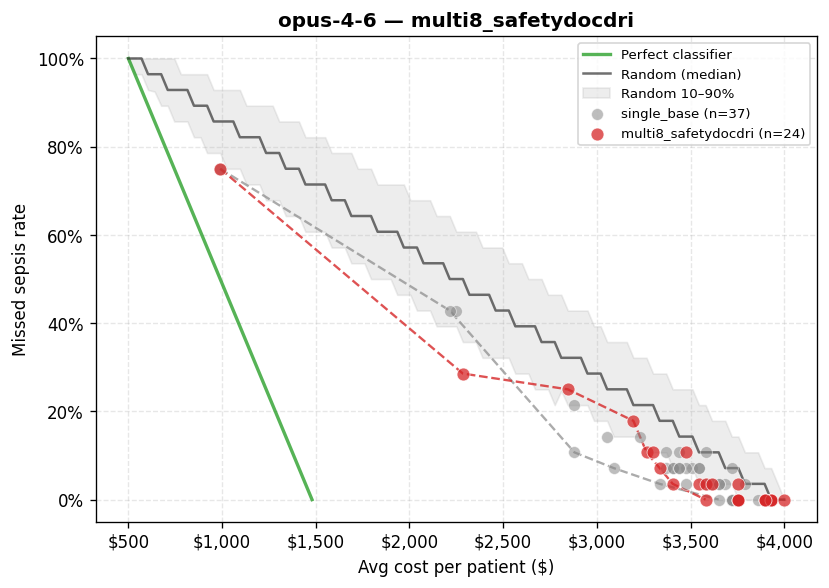

In [9]:
sample_orgs = [
    'multi8_base', 'multi8_comms', 'multi8_reviewpeer',
    'multi8_safetyreviewindep', 'multi8_dri',
    'multi8_safetydoc', 'multi8_safetydocdri',
]
sample_model = 'opus-4-6'
for org in sample_orgs:
    p = FIG_DIR / sample_model / f'{org}.png'
    if p.exists():
        display(Image(str(p)))